An Eigendiputados Session with python
==========
This exercise aims to demonstrate the use of scikit in python using an eigenfaces exercise. First will construct a class for storing the information of the chamber of representatives. You are invited to  import the image dataset, compute some descriptive statistics, perform an analysis of principal components, clustering analysis and finally will use a non-linear classifier to assess the gender from just the image of the representative. You are also invited to use your own dataset as validation dataset for the predictors. 


Diputado Class
-----
A diputado has a Name, Surnames, ID, Picture, Gender and Political Affiliation

In [2]:

class Diputado(object):
    def __init__(self,ind,fileRoot="./"):
        self.name=""
        self.surname=""
        self.ind=ind
        self.picfile=""
        self.party=""
        self.gender=""
        self.fileRoot=fileRoot
        self.ext="c.jpg" 
    def setName(self,name):
        self.name=name
    def setSurname(self,surname):
        self.surname=surname
    def setParty(self,party):
        self.party=party
    def setGender(self,gender):
        self.gender=gender
    def getName(self):
        return self.name
    def getSurname(self):
        return self.surname
    def getInd(self):
        return self.ind
    def getPicfile(self):
        return self.fileRoot + str(self.ind) + self.ext
    def getParty(self):
        return self.party
    def getGender(self):
        return self.gender
       

Parlament class
-----
Let's define a very simple Parlament object, where we store the diputados objects. From this class, we have to be able to get information from the parlament.

In [3]:
class Parlament(object):
    def __init__(self):
        self.elements=[]
        self.inds=[]
        self.ndips=0
    def add(self, diputado):
        self.elements.append(diputado)
        self.inds.append(diputado.getInd())
        self.ndips +=1
    def getInds(self):
        return [self.elements[i].getInd() for i in range(self.ndips)]
    def len(self):
        return len(self.elements)
    def __getitem__(self, key):
        if isinstance(key, slice):
            indices = key.indices(self.ndips)
            return [self[ii] for ii in xrange(*key.indices(self.len()))] 
        else:
            return self.elements[key]
    def getName(self,key):
        return self.elements[key].getName()
        

In [4]:
import os
os.getcwd() 
os.chdir('Z:/MSc Data Science Economics Universitat Barcelona/UPC - PDB Programming and Databases/Final Assignment Python')

Because the Spanish letters need include a lot of special characters, we need to add the `utf8` encoding when reading the csv file. 

In [5]:
import csv
with open('../datasets/db/index.csv','r', encoding="utf8") as csvfile:
    r = csv.reader(csvfile, delimiter=';')
    next(r)
    p = Parlament()
    for row in r:
        n = Diputado(int(row[0]),"../datasets/db/db/")
        n.setName(row[1].strip())
        n.setSurname(row[2].strip())
        n.setGender(row[3].strip())
        n.setParty(row[4].strip())
        p.add(n)

In [6]:
p.len()
p[99].getPicfile()

'db/db/91c.jpg'

In [7]:
p[99].name

'Francisco Xavier'

Let's create a dataset of the analysis.


'Joan | Tardà i Coma | H'

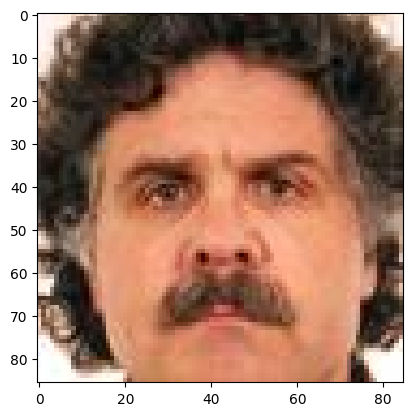

In [8]:
from scipy import ndimage,misc
import numpy as np
import matplotlib.pyplot as pl
idip = 129
I = pl.imread(p[idip].getPicfile())
pl.imshow(I)
np.shape(I)
' | '.join([p[idip].getName(), p[idip].getSurname(), p[idip].getGender()])

86


array([[250, 244, 248, ..., 220, 234, 236],
       [250, 243, 244, ..., 213, 229, 236],
       [247, 243, 243, ..., 207, 228, 242],
       ...,
       [255, 255, 255, ..., 254, 254, 254],
       [255, 255, 255, ..., 254, 254, 254],
       [255, 255, 253, ..., 254, 254, 254]], dtype=uint8)

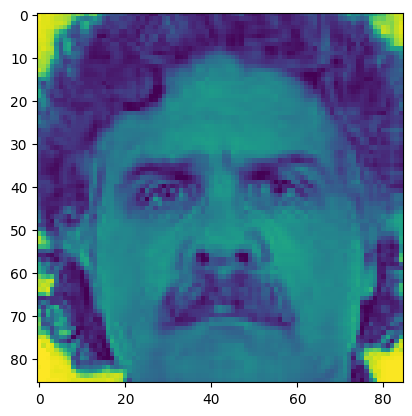

In [9]:
print(len(pl.imread(p[idip].getPicfile()).mean(axis=2)))
I_lum = I[: ,: , 2]
pl.imshow(I_lum)
I[: ,: , 2]


In [10]:
pl.imread(p[idip].getPicfile())

array([[[255, 247, 250],
        [253, 243, 244],
        [255, 248, 248],
        ...,
        [255, 234, 220],
        [255, 246, 234],
        [255, 246, 236]],

       [[255, 247, 250],
        [252, 242, 243],
        [255, 244, 244],
        ...,
        [246, 227, 213],
        [255, 241, 229],
        [255, 245, 236]],

       [[255, 246, 247],
        [254, 244, 243],
        [255, 245, 243],
        ...,
        [235, 217, 207],
        [253, 236, 228],
        [255, 248, 242]],

       ...,

       [[253, 253, 255],
        [254, 255, 255],
        [252, 255, 255],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]],

       [[255, 254, 255],
        [255, 255, 255],
        [254, 255, 255],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]],

       [[255, 254, 255],
        [254, 254, 255],
        [252, 254, 253],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]]

(86, 85)

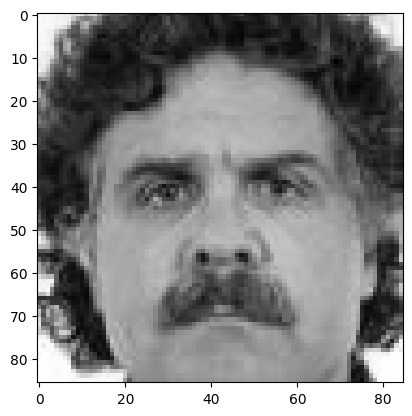

In [11]:
I = pl.imread(p[idip].getPicfile()).mean(axis=2)
img=pl.imshow(I)
img.set_cmap('gray')
Is=I.shape
Is

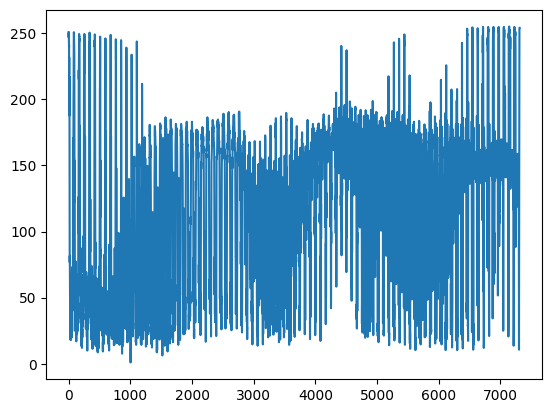

In [12]:
Iv = np.reshape(I,np.prod(Is)) # same as np.ravel()
pl.plot(Iv)

Let's stack all images to an array and create a couple of dependent variables.

In [14]:
X=np.array([ pl.imread(d.getPicfile()).mean(axis=2).ravel()
             for d in p])
Yg = np.array([ d.getGender() for d in p])
Yp = np.array([ d.getParty() for d in p])
Yp[0:5],Yg[0:5],X.shape

(array(['GS', 'GS', 'GC-CiU', 'GP', 'GP'], dtype='<U10'),
 array(['H', 'M', 'H', 'H', 'H'], dtype='<U1'),
 (348, 7310))

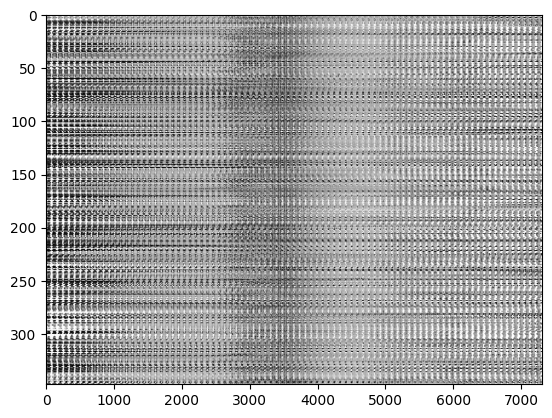

In [16]:
pl.figure()
pl.imshow(X,aspect='auto')
pl.set_cmap('gray')
